# 01 - Data Acquisition & Exploratory Data Analysis

I will load the Cleveland dataset and check a few rows and basic summaries first. This will give me a quick sense of the file’s structure before cleaning.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Could not find the project root containing the src folder.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import download_dataset, load_dataset

DATASET_PATH = PROJECT_ROOT / "data" / "heart_disease.csv"

# Download the dataset if it is not already available, then load it.
download_dataset(DATASET_PATH)
df_raw = load_dataset(DATASET_PATH)

print("First five rows before numeric validation:")
display(df_raw.head())

# These columns are expected to contain numeric values or numeric category codes.
# Keep the original values so we can report any entries that fail conversion.
df = df_raw.copy()
invalid_values_found = False

for col in df_raw.columns:
    converted_col = pd.to_numeric(df_raw[col], errors="coerce")
    invalid_mask = df_raw[col].notna() & converted_col.isna()

    if invalid_mask.any():
        invalid_values_found = True
        print(f"\nValues that could not be converted to numbers in '{col}':")
        print(df_raw.loc[invalid_mask, col].value_counts().head(10))

        # Show source row numbers (the CSV has no header row).
        source_rows = (df_raw.index[invalid_mask] + 1).tolist()
        print("CSV row numbers (first 10):", source_rows[:10])

    # Use the numeric version for the remaining EDA.
    df[col] = converted_col

if not invalid_values_found:
    print("\nNo non-empty, non-numeric values were found.")

print("\nData types after conversion:")
print(df.dtypes)

print("\nMissing values after conversion:")
missing_values = df.isna().sum()
print(missing_values[missing_values > 0] if missing_values.any() else "None")

print("\nSummary statistics:")
display(df.describe().T)

print("\nOriginal target counts:")
print(df["target"].value_counts(dropna=False).sort_index())

print("\nOriginal target proportions:")
print(df["target"].value_counts(normalize=True, dropna=False).sort_index())

First five rows before numeric validation:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Values that could not be converted to numbers in 'ca':
ca
?    4
Name: count, dtype: int64
CSV row numbers (first 10): [167, 193, 288, 303]

Values that could not be converted to numbers in 'thal':
thal
?    2
Name: count, dtype: int64
CSV row numbers (first 10): [88, 267]

Data types after conversion:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Missing values after conversion:
ca      4
thal    2
dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Original target counts:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Original target proportions:
target
0    0.541254
1    0.181518
2    0.118812
3    0.115512
4    0.042904
Name: proportion, dtype: float64


The file contains 303 records and 14 columns. The initial null check reports no missing values, but ? are present in 2 columns - ca and tha, so they need to be converted before pandas can count them as missing.

Converting '?' to a proper NA (or missing value)

In [2]:
df = load_dataset(DATASET_PATH)
df = df.replace("?", pd.NA).apply(pd.to_numeric, errors="coerce")

The ? values are now represented as missing values. I’ll keep these missing entries visible during EDA rather than filling them here.

Now, checking dimensions, data types, missing values, duplicates, and summary statistics to identify data-quality issues before exploring patterns.

In [3]:
print("Shape:", df.shape)
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary:")
display(df.describe().T)

Shape: (303, 14)
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Duplicate rows: 0

Summary:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


The dataset has 303 rows and 14 columns, with no exact duplicate rows. Missing entries appear in ca (4) and thal (2). These will need to be handled during model preprocessing; the summary also shows that the target still has its original 0–4 values at this stage.

The data dictionary identifies which fields are categorical and which are numeric. I’m checking distinct values of categorical fields so I don’t interpret category codes as measurements. The `ca` feature is a numeric vessel count from 0 to 3; `thal` is categorical despite its numeric codes.

In [4]:
coded_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
for col in coded_cols:
    print(col, sorted(df[col].dropna().unique()))

sex [np.float64(0.0), np.float64(1.0)]
cp [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
fbs [np.float64(0.0), np.float64(1.0)]
restecg [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
exang [np.float64(0.0), np.float64(1.0)]
slope [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
thal [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


These fields take a limited set of category codes, so I’ll interpret them as categories rather than assuming gaps between their codes have numeric meaning. In contrast, `ca` counts the number of major vessels (0-3), so I include it with numeric features.

The assignment asks for a binary outcome, while the original target has values from 0 to 4. I’m grouping 0 as disease absent and values above 0 as disease present.

In [5]:
print(df["target"].value_counts(dropna=False).sort_index())

# In this dataset, 0 means no disease and 1-4 indicate disease presence.
df["target"] = (df["target"] > 0).astype(int)

print("\nBinary target counts:")
print(df["target"].value_counts().sort_index())
print("\nBinary target proportions:")
print(df["target"].value_counts(normalize=True).sort_index())

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Binary target counts:
target
0    164
1    139
Name: count, dtype: int64

Binary target proportions:
target
0    0.541254
1    0.458746
Name: proportion, dtype: float64


After grouping the original labels, there are 164 records with target 0 and 139 with target 1—about 54.1% and 45.9%. The classes are fairly close in size, though I’ll still consider class-sensitive metrics when evaluating models.

I’m plotting the binary target counts to make the class distribution easier to compare visually.

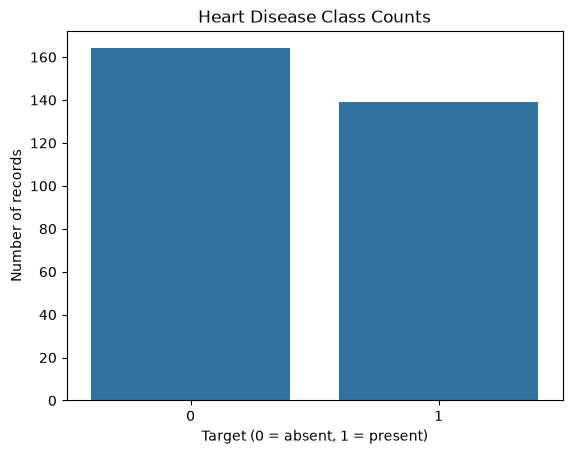

In [6]:
sns.countplot(data=df, x="target")
plt.title("Heart Disease Class Counts")
plt.xlabel("Target (0 = absent, 1 = present)")
plt.ylabel("Number of records")
plt.show()

The plot shows both classes are represented in substantial numbers, with somewhat more target-0 records. This supports using a stratified train/test split so the class proportions are preserved.

I’m using histograms to inspect numeric measurements and the discrete `ca` vessel count. This helps show their distributions, skew, and unusual values without treating categorical codes as measured quantities.

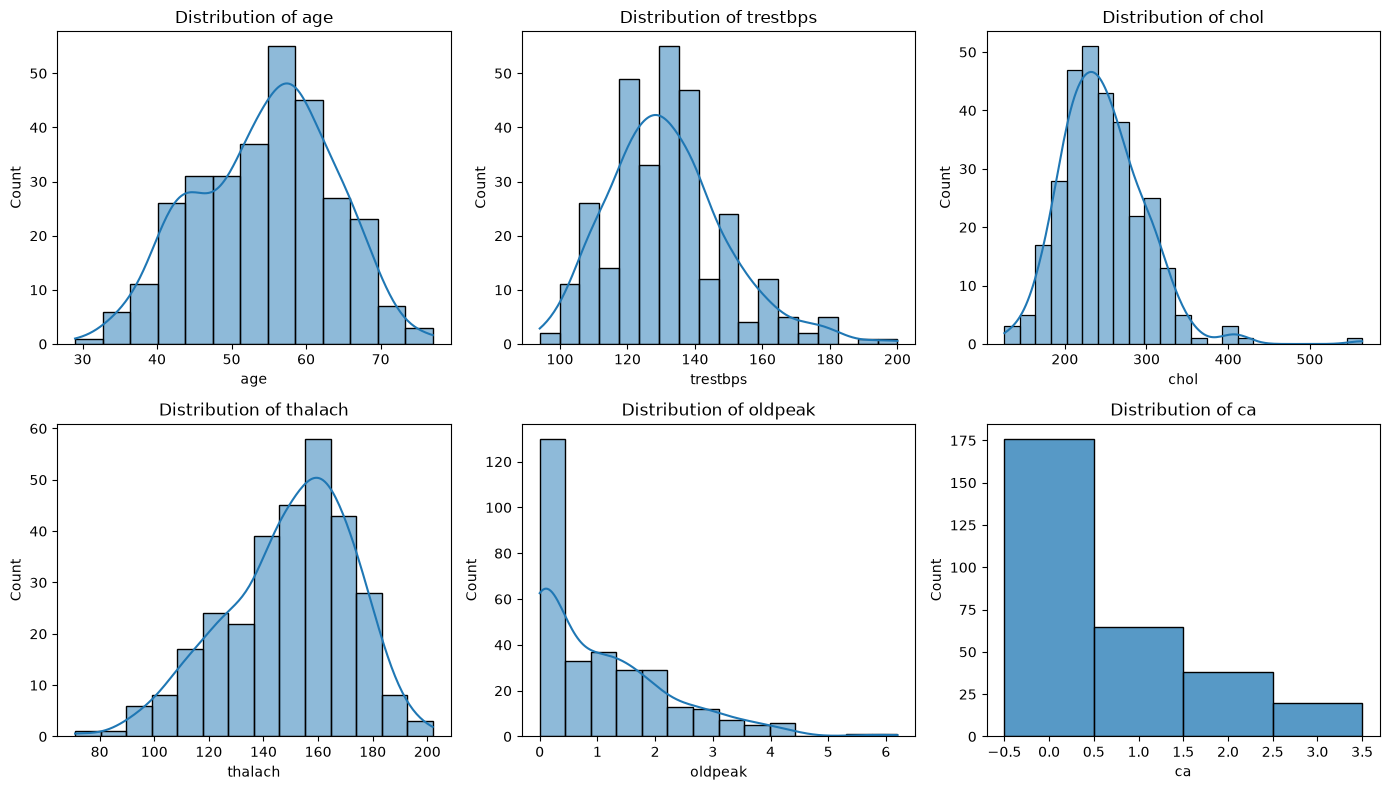

In [7]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(numeric_cols, axes.flat):
    sns.histplot(data=df, x=col, discrete=(col == "ca"), kde=(col != "ca"), ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

The distributions are not all symmetric: cholesterol and oldpeak are right-skewed, while age looks comparatively balanced. The `ca` plot is shown as a discrete count because it records 0-3 vessels.

I’m comparing each numeric feature, including the discrete vessel count `ca`, across both target classes. Separate panels let each feature retain its own scale, making differences in medians, spread, and outliers easier to inspect.

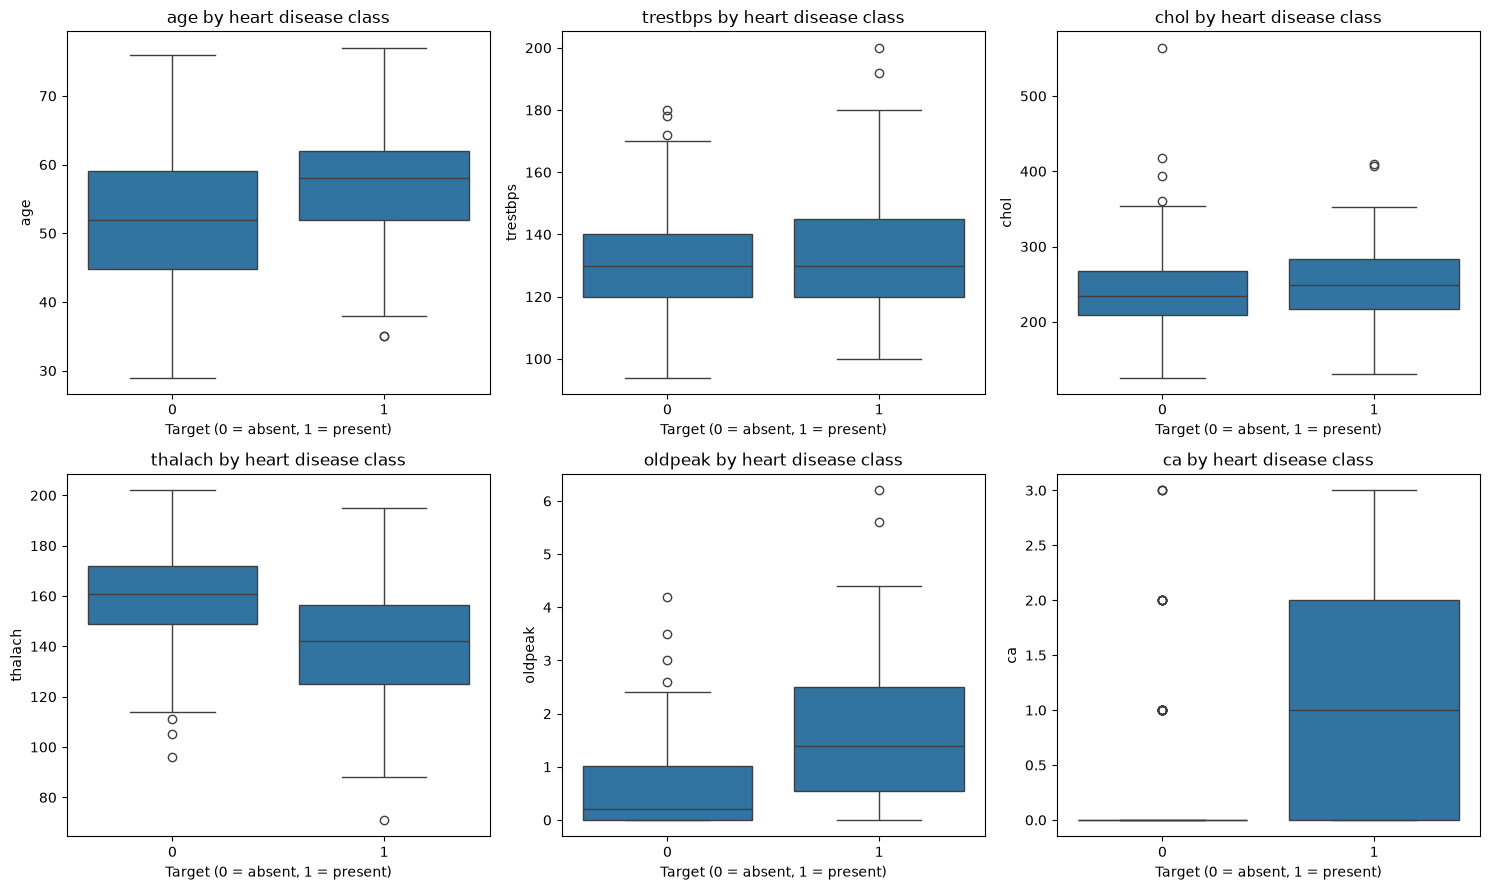

In [8]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, ax in zip(numeric_cols, axes.flat):
    sns.boxplot(
        data=df,
        x="target",
        y=col,
        order=[0, 1],
        ax=ax,
    )
    ax.set_title(f"{col} by heart disease class")
    ax.set_xlabel("Target (0 = absent, 1 = present)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

The boxplots show some differences between the two target groups. The disease-present group has higher medians for age, oldpeak, and the numeric vessel count `ca`, and a lower median maximum heart rate (`thalach`). Resting blood pressure (`trestbps`) has similar medians in both groups, while cholesterol (`chol`) shows substantial overlap and several high outliers. These are patterns in this dataset, not evidence of causation or proof that a feature will predict disease on its own.

Now I’ll plot a heatmap to summarize linear correlations among numeric measurements/counts and the binary target. I’ve left categorical features out because their numeric labels can make Pearson correlations harder to interpret. Since `ca` is a count from 0 to 3, interpret its correlation as a simple exploratory trend.

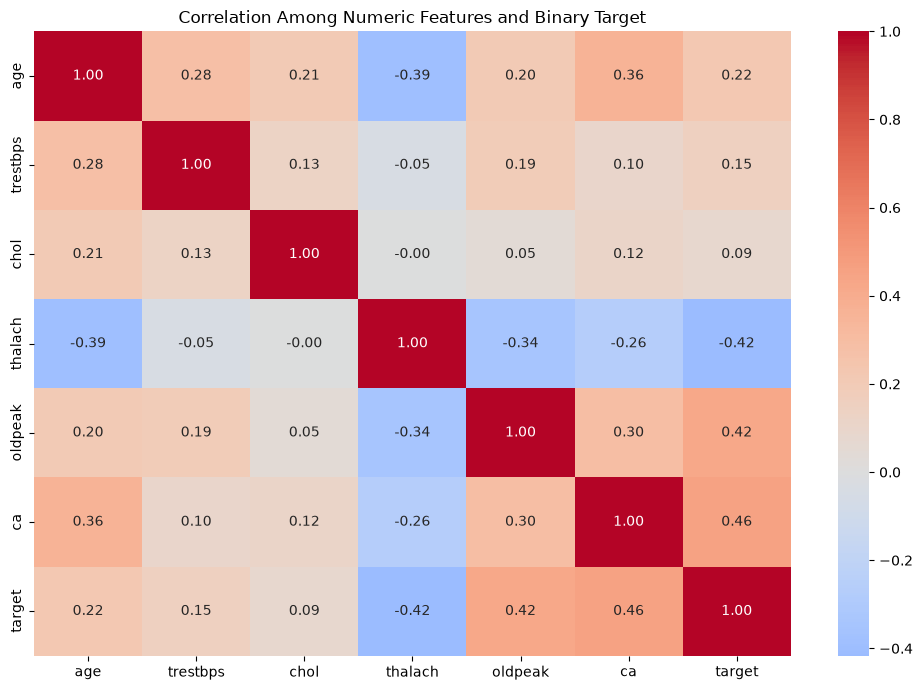

In [9]:
heatmap_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "target"]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[heatmap_cols].corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
)
plt.title("Correlation Among Numeric Features and Binary Target")
plt.tight_layout()
plt.show()

In this sample, the heatmap shows correlations of about 0.46 between the numeric count `ca` and the binary target, 0.42 between oldpeak and the target, and -0.42 between thalach and the target. These are exploratory associations, not evidence of causation; the heatmap also does not capture every kind of relationship.

## EDA summary

The Cleveland Heart Disease dataset contains 303 records and 14 columns. The source target has five values (0-4); for this assignment, I grouped 0 as disease absent and values 1-4 as disease present. This gives 164 records in class 0 (54.1%) and 139 in class 1 (45.9%), so the binary classes are reasonably balanced.

Following the data dictionary, I treat age, trestbps, chol, thalach, oldpeak, and ca as numeric features; ca is a count of major vessels from 0 to 3. I treat sex, cp, fbs, restecg, exang, slope, and thal as categorical. The data check found no exact duplicate rows. Six values were not numeric: four in ca and two in thal. I retained these as missing values for EDA; they should be imputed within the model preprocessing pipeline, fitted on training data only.

The histograms show that cholesterol and oldpeak are right-skewed, while age is comparatively balanced. The feature-by-target boxplots show a higher median age, oldpeak, and ca count, and a lower median maximum heart rate (thalach), in the disease-present group. Resting blood pressure has similar medians across the groups, and cholesterol distributions overlap, with several high outliers. These are descriptive patterns in this dataset; unusual observations should be investigated rather than removed automatically.

The correlation heatmap shows simple numeric associations between the binary target and ca (about 0.46), oldpeak (about 0.42), and thalach (about -0.42). Correlations for age, resting blood pressure, and cholesterol are weaker in this view. Since ca is a discrete count, its Pearson correlation should be treated as an exploratory trend. Correlations do not establish causation, and categorical features are excluded because their numeric labels can make Pearson correlations misleading.